# Pipeline Sensor Anomaly Detection Using Data Science

**An end-to-end, reproducible anomaly-detection study on synthetic pipeline-style sensor data.**

> **Disclosure.** Every number in this notebook comes from a **simulator** written for this project
> (`src/pipeline_anomaly/data_generation.py`). Nothing here was measured on a real pipeline, the segment and
> sensor identifiers are invented, and the evaluation only tells us how well each method recovers the anomaly
> patterns that the simulator injected. This is an analytics and learning exercise. It is **not** a leak-detection,
> safety or operational-intervention system, and a flagged observation is only a candidate for human review.

**Contents**

1. Setup
2. Data acquisition
3. Data validation and cleaning
4. Exploratory data analysis
5. Feature engineering
6. Anomaly detection models
7. Evaluation
8. Interpretation: what gets flagged, what gets missed
9. How this could support analysts
10. Limitations and next steps

## 1. Setup

In [1]:
import sys, json, warnings
from pathlib import Path

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():          # notebook is run from notebooks/
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from pipeline_anomaly import config as cfg, pipeline, visualization as viz, evaluation as ev
from pipeline_anomaly.data_generation import write_dataset, EVENTS_PER_SEGMENT_90D, NOISE_SD
from pipeline_anomaly.data_loading import load_raw
from pipeline_anomaly.validation import validate, clean
from pipeline_anomaly.features import MODEL_FEATURES, CLASSIC_ZSCORE_FEATURES

viz.set_style()
pd.set_option("display.max_columns", 40, "display.width", 200, "display.precision", 3)
print("Project root:", ROOT.name)

Project root: pipeline-sensor-anomaly-detection


## 2. Data acquisition

### Why synthetic data?

Public datasets were considered first (details in `docs/dataset_investigation.md`): the Skoltech Anomaly Benchmark
(a water-circulation test rig), the Numenta Anomaly Benchmark, NASA's SMAP/MSL telemetry and the Tennessee Eastman
process simulation. None of them is a transmission pipeline with segment identifiers, operating states and the
pressure / flow / temperature trio, and real pipeline SCADA data is commercially and security sensitive, so it is
not published. A purpose-built simulator gives pipeline-style structure, known ground truth for every anomaly, and
full reproducibility, at the cost of realism. That trade-off is stated wherever results are reported.

### What the simulator produces

* **4 segments in series** (`SEG-A` … `SEG-D`), each with one instrument station, sampled every **5 minutes for 180 days**.
* **Operating states** `NORMAL`, `HIGH_FLOW`, `LOW_FLOW`, `SHUTDOWN` that change every few hours to days.
* **Physics-inspired normal behaviour**: flow follows the commanded state with a short lag and a mild daily cycle;
  pressure = static head + friction term proportional to flow²; temperature = seasonal + daily cycle + frictional
  heating with a ~2 h thermal lag; all with autocorrelated noise.
* **Six labelled anomaly patterns** (spike, pressure–flow deviation, drift, flatline, noise burst, temperature excursion).
* **Data-quality defects** (missing cells, missing rows, duplicate rows, `-999` sentinel values) so that validation
  has something real to find.

The generator is deterministic for a given seed. The next cell regenerates the raw file from scratch.

In [2]:
raw_generated, manifest = write_dataset(cfg.RAW_FILE)     # deterministic: seed = cfg.RANDOM_SEED
print(json.dumps(manifest, indent=2))

{
  "synthetic": true,
  "seed": 42,
  "days": 180,
  "start": "2025-01-01",
  "sample_minutes": 5,
  "segments": [
    "SEG-A",
    "SEG-B",
    "SEG-C",
    "SEG-D"
  ],
  "rows_before_defects": 207360,
  "anomalous_rows_before_defects": 7395,
  "events_per_segment": {
    "spike": 60,
    "pressure_flow_deviation": 10,
    "drift": 6,
    "flatline": 8,
    "noise_burst": 8,
    "temperature_excursion": 6
  },
  "defects": {
    "missing_cells": 1771,
    "sentinel_cells": 40,
    "dropped_rows": 53,
    "duplicate_rows": 207
  },
  "rows_written": 207514
}


In [3]:
raw = load_raw(cfg.RAW_FILE)
print(f"{len(raw):,} rows x {raw.shape[1]} columns")
raw.head()

207,514 rows x 11 columns


,timestamp,segment_id,sensor_id,pressure_kpa,flow_m3h,temperature_c,operating_state,is_anomaly,anomaly_type,anomaly_event_id,anomaly_sensor
0,2025-01-01 00:00:00,SEG-A,STN-101,3977.5,767.78,12.246,NORMAL,0,none,,
1,2025-01-01 00:05:00,SEG-A,STN-101,3958.1,778.92,12.201,NORMAL,0,none,,
2,2025-01-01 00:10:00,SEG-A,STN-101,3960.8,783.71,12.276,NORMAL,0,none,,
3,2025-01-01 00:15:00,SEG-A,STN-101,3971.2,780.33,12.113,NORMAL,0,none,,
4,2025-01-01 00:20:00,SEG-A,STN-101,3982.3,783.51,12.213,NORMAL,0,none,,


## 3. Data validation and cleaning

`validate()` only *inspects*; `clean()` applies documented fixes and returns a log. Because the simulator records how
many defects it injected, we can check that validation actually finds them.

In [4]:
report = validate(raw)
summary = pd.Series({
    "rows": report["n_rows"],
    "exact duplicate rows": report["exact_duplicate_rows"],
    "duplicate (segment, timestamp) keys": report["duplicate_keys"],
    "unparseable timestamps": report["unparseable_timestamps"],
    "missing timestamps (all segments)": sum(s["missing_timestamps"] for s in report["segments"].values()),
    "unknown operating states": report["unknown_operating_states"],
    "label inconsistencies": report["label_inconsistencies"],
}, name="count")
display(summary.to_frame())
display(pd.DataFrame({"missing": report["missing_values"], "dtype": report["dtypes"]}).join(
    pd.Series(report["invalid_values"], name="out_of_range")).fillna(""))
display(pd.DataFrame(report["segments"]).T)
print("Injected by the simulator:", manifest["defects"])

,count
rows,207514
exact duplicate rows,207
"duplicate (segment, timestamp) keys",207
unparseable timestamps,0
missing timestamps (all segments),53
unknown operating states,0
label inconsistencies,0


,missing,dtype,out_of_range
timestamp,0,datetime64[ns],
segment_id,0,object,
sensor_id,0,object,
pressure_kpa,545,float64,13.0
flow_m3h,640,float64,10.0
temperature_c,588,float64,17.0
operating_state,0,object,
is_anomaly,0,int64,
anomaly_type,0,object,
anomaly_event_id,0,object,


,start,end,rows,unique_timestamps,expected_timestamps,missing_timestamps,coverage_pct,is_sorted,off_grid_intervals,largest_gap_minutes
SEG-A,2025-01-01 00:00:00,2025-06-29 23:55:00,51878,51824,51840,16,99.969,True,0,50.0
SEG-B,2025-01-01 00:00:00,2025-06-29 23:55:00,51878,51822,51840,18,99.965,True,0,55.0
SEG-C,2025-01-01 00:00:00,2025-06-29 23:55:00,51886,51828,51840,12,99.977,True,0,50.0
SEG-D,2025-01-01 00:00:00,2025-06-29 23:55:00,51872,51833,51840,7,99.986,True,0,25.0


Injected by the simulator: {'missing_cells': 1771, 'sentinel_cells': 40, 'dropped_rows': 53, 'duplicate_rows': 207}


**Findings.** Validation recovers the injected duplicate rows and missing timestamps exactly, and finds the
out-of-range sentinel values and scattered missing cells. Timestamps are on a regular 5-minute grid with coverage
above 99.9 % per segment; types are as expected.

**Cleaning decisions** (implemented in `validation.clean`, each one covered by a unit test):

| Issue | Decision | Reason |
|---|---|---|
| Exact duplicate rows | Drop | A re-sent record carries no new information |
| Out-of-range values (e.g. `-999`) | Set to missing | Instrument artefact, not process behaviour; must not be scored as a process anomaly |
| Missing timestamps | Insert explicit rows, flag `row_inserted` | Rolling windows assume a regular grid |
| Missing sensor values | **Forward-fill**, at most 1 hour | Interpolation would use the *next* reading, which a live monitor would not have yet (look-ahead) |
| Still-missing rows | Flag `usable = False` | Excluded from modelling rather than guessed |
| Inserted rows | Excluded from evaluation | There is no real observation to judge |

In [5]:
clean_df, cleaning_log = clean(raw)
display(pd.Series({k: v for k, v in cleaning_log.items() if not isinstance(v, dict)}, name="count").to_frame())
print("Invalid values set to missing:", cleaning_log["invalid_values_set_missing"])

,count
rows_in,207514
dropped_unparseable_timestamps,0
dropped_exact_duplicates,207
dropped_conflicting_duplicate_keys,0
inserted_rows_for_missing_timestamps,53
sensor_cells_forward_filled,1969
rows_not_usable,0
rows_out,207360


Invalid values set to missing: {'pressure_kpa': 13, 'flow_m3h': 10, 'temperature_c': 17}


## 4. Exploratory data analysis

The remaining stages are run through `pipeline.prepare_data()`, which repeats loading, validation and cleaning and
then adds the features and the chronological split (60 % train / 20 % validation / 20 % test).

In [6]:
prep = pipeline.prepare_data(regenerate=False)
feats = prep.features
print(f"Clean grid: {len(feats):,} rows | validation starts {prep.val_start:%Y-%m-%d} | test starts {prep.test_start:%Y-%m-%d}")
feats.loc[feats["usable"], cfg.SENSOR_COLS].describe().T

Clean grid: 207,360 rows | validation starts 2025-04-19 | test starts 2025-05-25


,count,mean,std,min,25%,50%,75%,max
pressure_kpa,207360.0,3235.882,768.310,1018.500,2653.700,3116.600,3882.60,5551.700
flow_m3h,207360.0,769.343,142.191,0.000,776.180,793.760,812.30,1092.640
temperature_c,207360.0,12.898,1.400,5.738,11.995,12.952,13.86,19.856


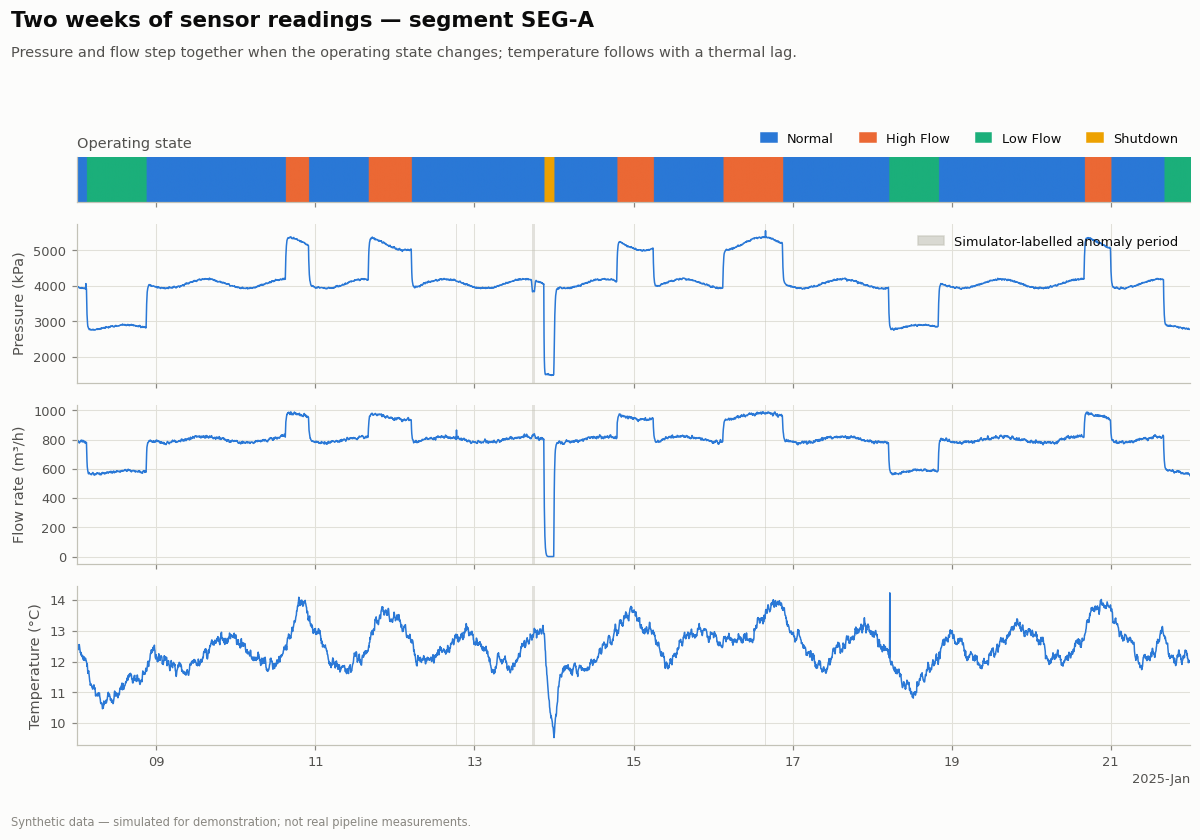

In [7]:
viz.fig_sensor_overview(feats); plt.show()

**What this shows.** Two weeks for one segment. Pressure and flow change level together whenever the operating state
changes, and temperature follows more slowly. The largest movements in the data are *legitimate*: a state change is
far bigger than any anomaly. A detector that only looks at raw levels would flag every shutdown.

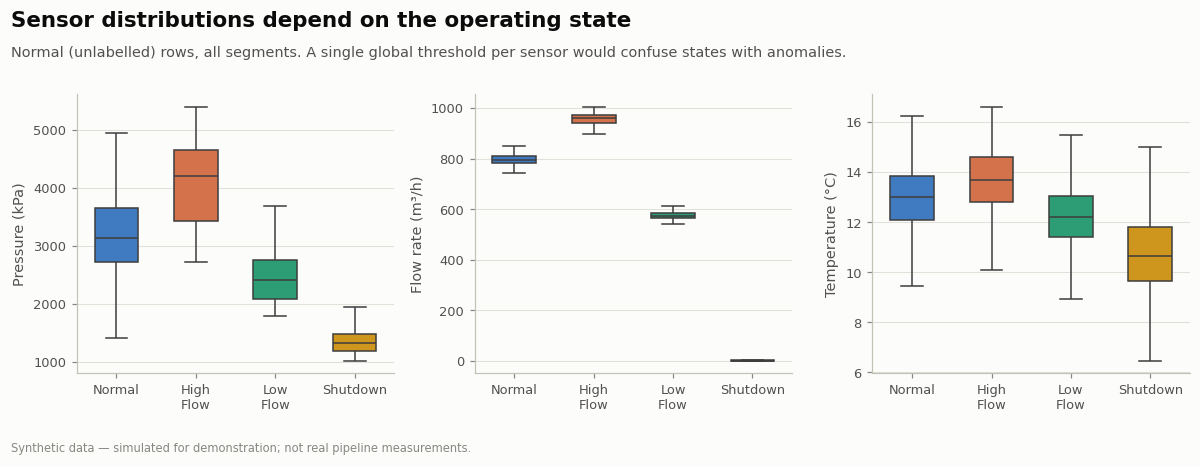

In [8]:
viz.fig_distributions_by_state(feats); plt.show()

**What this shows.** Each state has its own distribution for every sensor. This is why raw sensor values are not fed
to the models: "unusual" has to mean *unusual given the current operating context*.

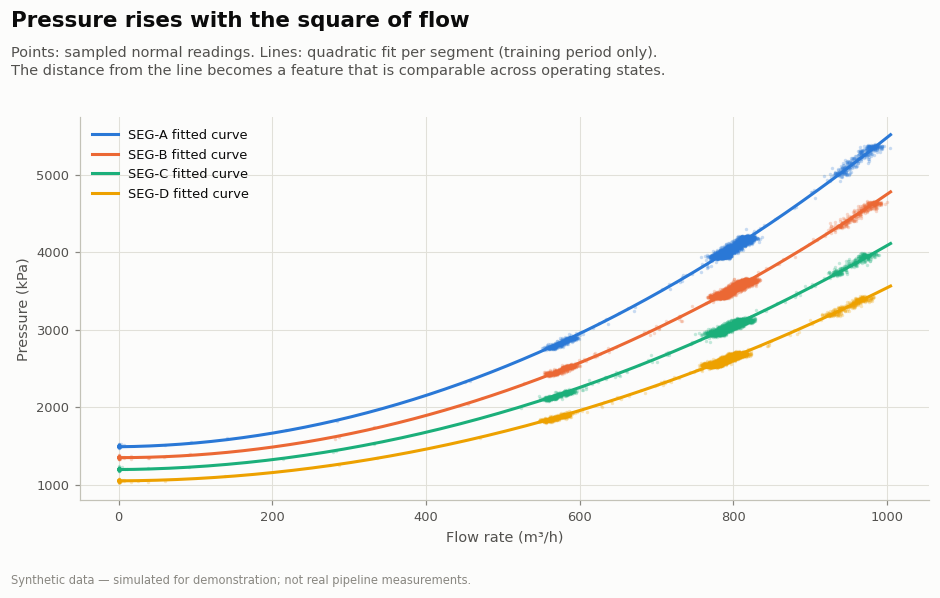

In [9]:
viz.fig_pressure_flow(feats, prep.pf_model); plt.show()

**What this shows.** Within a segment, pressure is close to a quadratic function of flow across all states. The
fitted curve (training period only) lets us compute an *expected* pressure for any flow; the residual is a feature
that stays near zero in every state and moves when the relationship breaks.

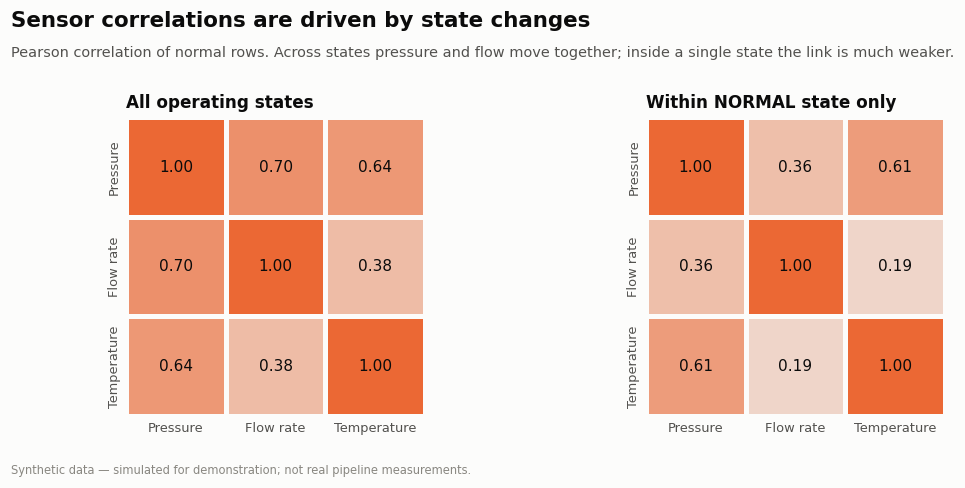

In [10]:
viz.fig_correlations(feats); plt.show()

**What this shows.** The raw pressure–flow correlation looks strong, but it is mostly created by state changes.
Inside the `NORMAL` state it is much weaker because noise dominates the small within-state movements. Correlation
on its own is a poor guide here; the physical relationship is a better one.

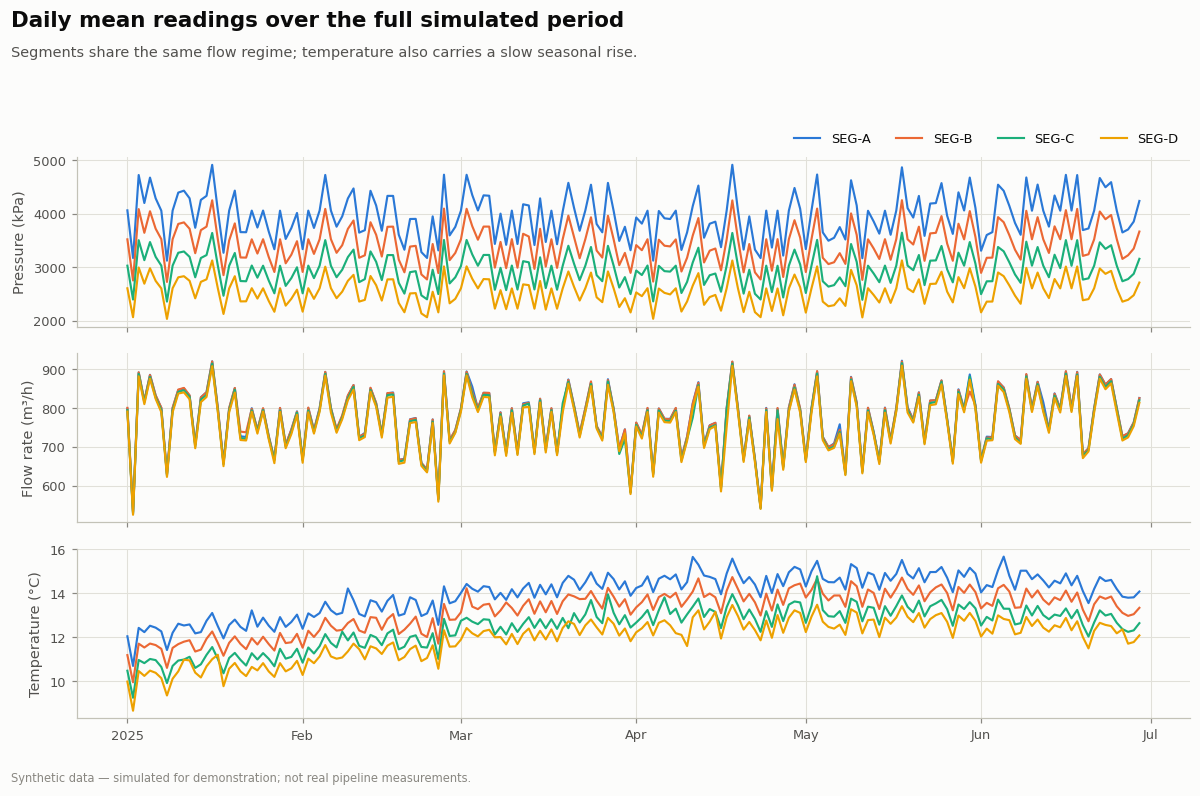

In [11]:
viz.fig_temporal_trends(feats); plt.show()

**What this shows.** Daily means over the whole period. All segments share the same flow regime (they are in
series) at different pressure levels, and temperature carries a slow seasonal rise. A slow, legitimate trend like
this is one reason fixed global thresholds age badly.

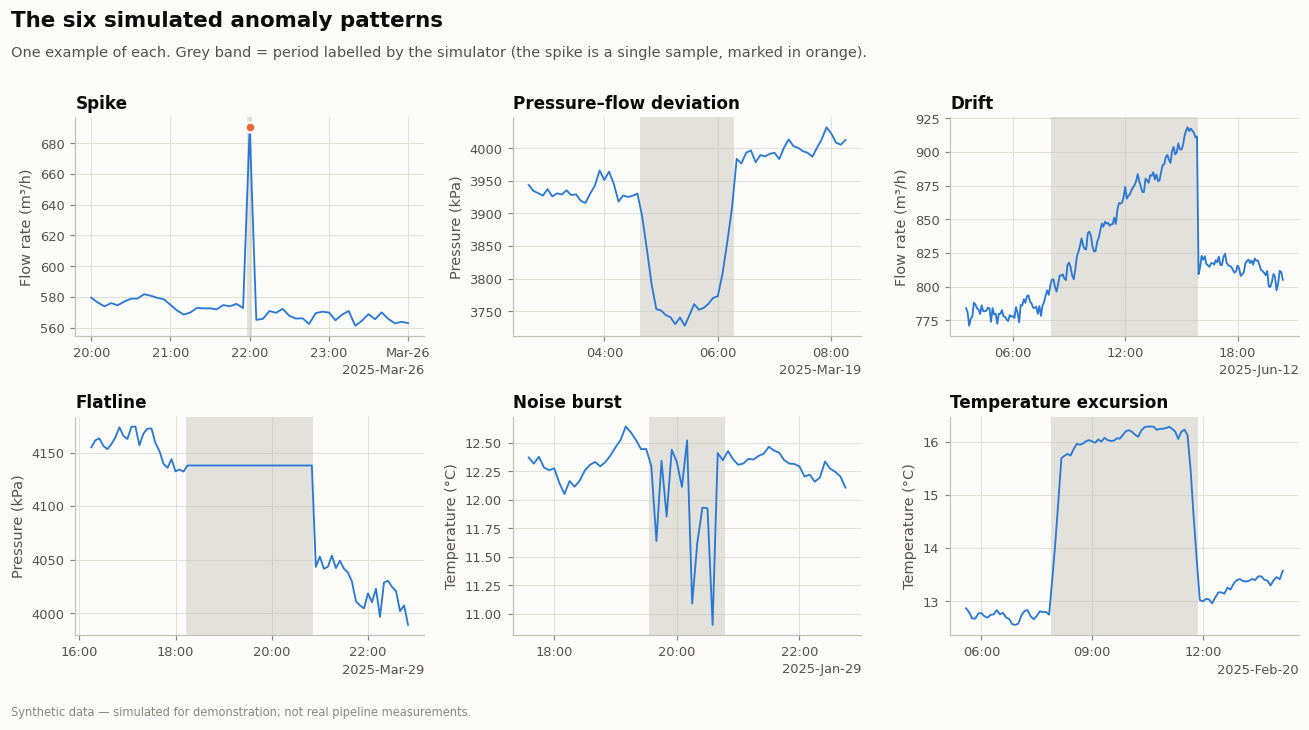

In [12]:
viz.fig_anomaly_examples(feats); plt.show()

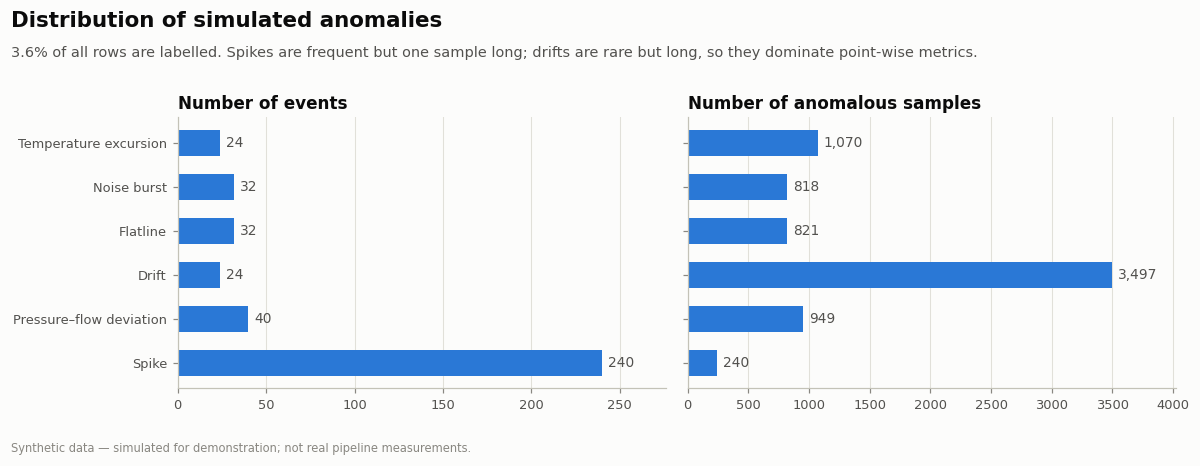

In [13]:
viz.fig_label_distribution(feats); plt.show()

**What these show.** The six simulated patterns and how often they occur. Spikes are numerous but a single sample
each; drifts are few but long, so they account for the largest share of anomalous *samples*. That matters for
evaluation: point-wise metrics are dominated by how much of each long drift is flagged, which is why event-level
recall is reported alongside.

## 5. Feature engineering

**Rule: a feature at time *t* uses only readings at or before *t*.** Windows are trailing, baselines are shifted by
one sample, and the pressure–flow curve is fitted on the training period only. A unit test
(`test_no_look_ahead`) changes the future and asserts that no past feature moves.

| Family | Features | Purpose |
|---|---|---|
| Lags and changes | `*_lag_1`, `*_lag_1h`, `*_diff_1`, `*_diff_1h` | Sudden jumps |
| Rolling statistics | `*_roll_mean_1h/6h`, `*_roll_std_1h/6h` | Local level and spread |
| Classic z-score | `*_z_6h` | Deviation from 6 h mean / std (kept for comparison) |
| Robust z-score | `*_rz_1h` | Deviation from the 1 h median, scaled by the typical step size |
| EWMA residual | `*_ewma_resid` | Deviation from a smoothed forecast |
| Volatility ratio | `*_vol_ratio` | Unusually quiet (stuck) or unusually noisy sensor |
| Physics residual | `pf_resid_z`, `pf_resid_mean_1h`, `pf_resid_trend_3h` | Break or slow drift in the pressure–flow relationship |
| Trend | `temperature_trend_3h`, `pf_resid_trend_3h` | Slow movement |
| Context / time | `minutes_since_state_change`, `is_shutdown`, `hour_sin`, `hour_cos`, `day_of_week` | Operating and calendar context |

Two design decisions deserve explanation:

* **Raw levels, lags and rolling means are not given to the models.** They mostly encode the operating state.
* **Settling windows.** For 60 minutes after a commanded state change the sensors are expected to move, so those
  rows are *not monitored*: excluded from training and unable to raise an alert. Anomalies inside a settling window
  therefore count as missed. The cost and benefit of this rule are measured in section 7.

In [14]:
mf = prep.model_frame
print(f"{len(MODEL_FEATURES)} model features:", MODEL_FEATURES)
print(f"Rows that can be scored: {len(mf):,} | in a settling window: {int(mf['in_settling'].sum()):,} "
      f"({mf['in_settling'].mean():.1%}), of which labelled anomalous: {int((mf['in_settling'] & (mf['is_anomaly']==1)).sum())}")
mf.groupby("split").agg(rows=("is_anomaly", "size"), anomalous_rows=("is_anomaly", "sum"),
                        prevalence=("is_anomaly", "mean"),
                        events=("anomaly_event_id", lambda s: s[s != ""].nunique())).loc[["train", "val", "test"]]

16 model features: ['pressure_rz_1h', 'flow_rz_1h', 'temperature_rz_1h', 'pressure_diff_1', 'flow_diff_1', 'temperature_diff_1', 'pressure_ewma_resid', 'flow_ewma_resid', 'temperature_ewma_resid', 'pressure_vol_ratio', 'flow_vol_ratio', 'temperature_vol_ratio', 'pf_resid_z', 'pf_resid_mean_1h', 'pf_resid_trend_3h', 'temperature_trend_3h']
Rows that can be scored: 207,143 | in a settling window: 10,224 (4.9%), of which labelled anomalous: 328


,rows,anomalous_rows,prevalence,events
split,,,,
train,124233,5014,0.040,228
val,41438,1089,0.026,83
test,41472,1292,0.031,81


## 6. Anomaly detection models

All detectors share one interface (`fit`, `score`; higher = more unusual) and one thresholding rule, so they are
compared on equal terms.

| Detector | How it works | Strength | Weakness | Key parameters |
|---|---|---|---|---|
| **Rolling z-score** (statistical baseline) | Largest absolute robust z-score across the three sensors | Transparent, no training, easy to explain | Looks at one sensor at a time; blind to relationship breaks and to slow change | 1 h median baseline, 6 h scale window |
| **Isolation Forest** | Random trees; points isolated in few splits score high | Fast, few assumptions, handles many features | Scores are relative; weak on anomalies that are unusual in only one mild feature | 300 trees, 512 samples per tree |
| **Local Outlier Factor** (novelty mode) | Compares local density with that of the nearest training points | Finds points that are odd *locally* even if not extreme | Slow at scale (fitted on a 20 000-row subsample); anomalies in the training data can form their own "normal" clusters | 50 neighbours |
| **PCA reconstruction error** | Rebuild each row from the main principal components; large error = broken correlation structure | Classic multivariate process-monitoring tool, cheap, linear | Only sees linear structure; large-but-consistent deviations reconstruct well | Components explaining 90 % of variance |
| **Rank-average ensemble** | Mean of the four detectors' score percentiles | Simple way to combine incomparable scores | Averaging dilutes a detector that is uniquely right | none |

**Thresholding without labels.** In practice there are no labels to tune on. Each detector's threshold is the
97th percentile of its own training scores: an *alert budget* of 3 % of observations for analysts to review. A
second, label-informed threshold (best F1 on the validation period) is reported only as a reference.

Preprocessing for the three learned models: `RobustScaler` (median / IQR, because the training period itself
contains anomalies) followed by clipping to ±10.

In [15]:
scored = pipeline.fit_and_score(prep.model_frame)
pd.Series(scored.thresholds, name="alert threshold (score units)").to_frame()

,alert threshold (score units)
Rolling z-score,4.919
Isolation Forest,0.485
Local Outlier Factor,1.440
PCA reconstruction,4.018
Rank-average ensemble,0.908


## 7. Evaluation

Evaluated on the **held-out final 20 % of the timeline**, against the simulator's labels.

* **Point-wise** precision / recall / F1: every 5-minute sample is judged separately.
* **Event recall**: share of labelled events with at least one alert. Closer to how an analyst would use alerts.
* **ROC-AUC / PR-AUC**: threshold-free ranking quality. With ~3 % prevalence, PR-AUC is the more informative one.

> These figures describe detection of *simulated* patterns only. They are not an estimate of performance on real data.

In [16]:
results = pipeline.evaluate(scored)
pipeline.save_outputs(prep, scored, results)
cols = ["model", "precision", "recall", "f1", "false_positive_rate", "roc_auc", "pr_auc", "event_recall", "median_delay_minutes"]
print("Test period - label-free threshold (3% alert budget)")
display(results["comparison"][cols].set_index("model").round(3))

Test period - label-free threshold (3% alert budget)


,precision,recall,f1,false_positive_rate,roc_auc,pr_auc,event_recall,median_delay_minutes
model,,,,,,,,
Rolling z-score,0.197,0.192,0.195,0.025,0.603,0.141,0.840,0.0
Isolation Forest,0.371,0.365,0.368,0.020,0.845,0.258,0.852,0.0
Local Outlier Factor,0.362,0.357,0.359,0.020,0.703,0.236,0.926,0.0
PCA reconstruction,0.298,0.275,0.286,0.021,0.698,0.153,0.519,0.0
Rank-average ensemble,0.241,0.243,0.242,0.025,0.748,0.150,0.778,0.0


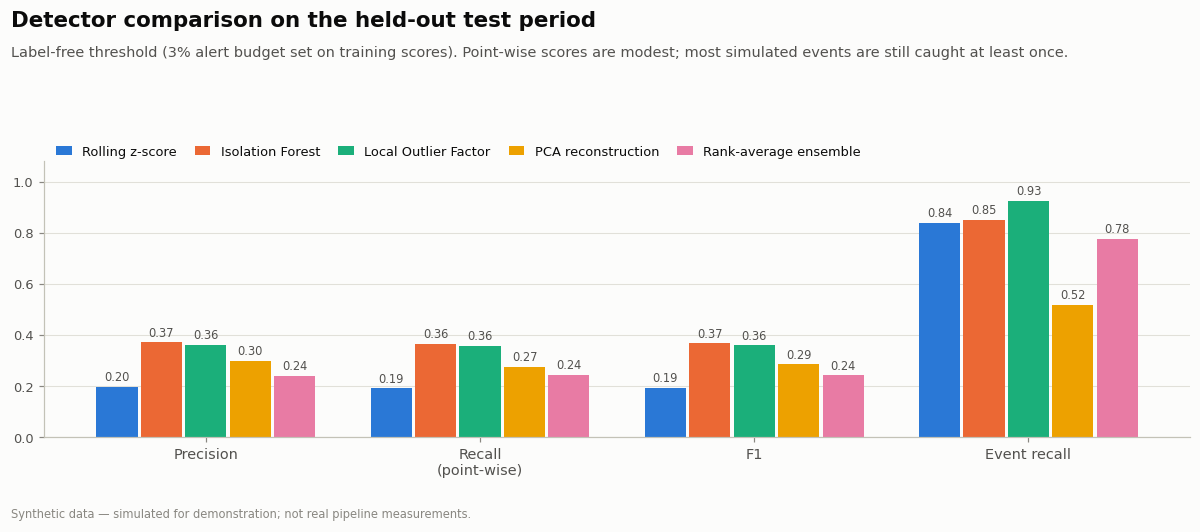

In [17]:
viz.fig_model_comparison(results['comparison']); plt.show()

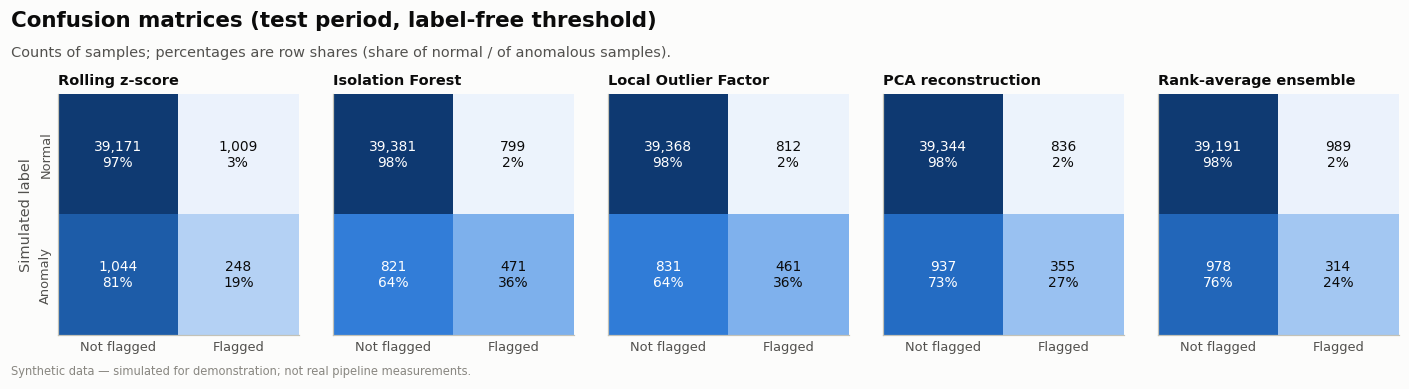

In [18]:
viz.fig_confusion_matrices(results['comparison']); plt.show()

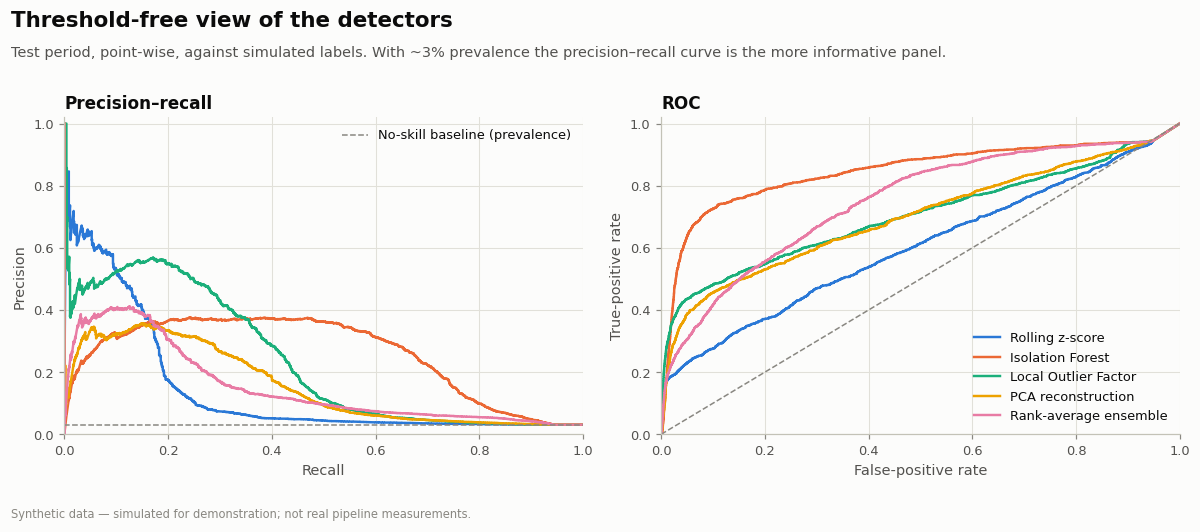

In [19]:
viz.fig_pr_roc(results['test']); plt.show()

**Reading the results.**

* Isolation Forest and Local Outlier Factor are the strongest at the operating threshold, roughly doubling the
  F1 of the per-sensor statistical baseline. Isolation Forest has clearly the best ranking quality (ROC-AUC, PR-AUC).
* Point-wise scores are modest for every method. Event recall is much higher: most simulated events trigger at
  least one alert even when only part of the event is flagged.
* The ensemble does **not** beat its best members. The detectors are good at different things, and averaging
  dilutes the one that is right.

In [20]:
print("Reference: threshold tuned on validation labels, applied to test")
display(results["comparison_tuned"][["model", "validation_f1", "precision", "recall", "f1", "event_recall"]].set_index("model").round(3))
print("Ablation: same detectors and thresholds WITHOUT the settling-window rule")
display(results["comparison_no_settling_mask"][["model", "precision", "recall", "f1", "event_recall"]].set_index("model").round(3))

Reference: threshold tuned on validation labels, applied to test


,validation_f1,precision,recall,f1,event_recall
model,,,,,
Rolling z-score,0.286,0.429,0.138,0.209,0.790
Isolation Forest,0.374,0.369,0.433,0.398,0.852
Local Outlier Factor,0.395,0.414,0.314,0.357,0.926
PCA reconstruction,0.283,0.314,0.254,0.281,0.481
Rank-average ensemble,0.281,0.334,0.192,0.244,0.691


Ablation: same detectors and thresholds WITHOUT the settling-window rule


,precision,recall,f1,event_recall
model,,,,
Rolling z-score,0.094,0.248,0.136,0.938
Isolation Forest,0.158,0.420,0.230,0.938
Local Outlier Factor,0.167,0.411,0.238,1.000
PCA reconstruction,0.136,0.327,0.192,0.605
Rank-average ensemble,0.114,0.298,0.165,0.864


**Two checks on the design.**

* Tuning the threshold with labels changes F1 only slightly, so the label-free alert budget is not what limits performance.
* Removing the settling-window rule raises recall a little and lowers precision a lot: without it, state changes
  flood the alert list. The rule is a deliberate trade: fewer false alarms in exchange for a known blind spot.

## 8. Interpretation: what gets flagged, what gets missed

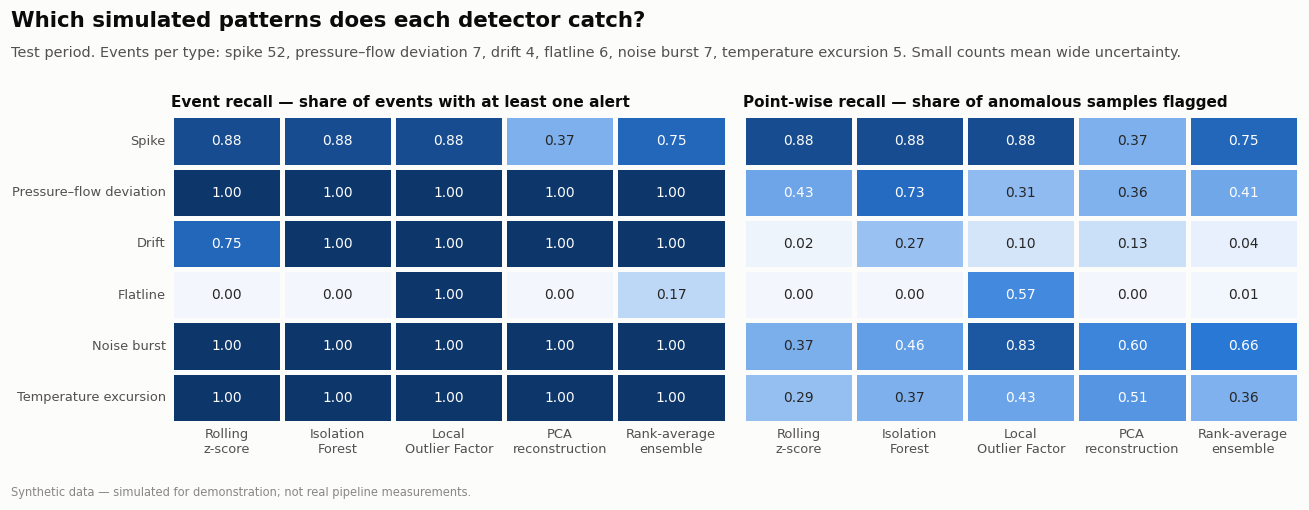

In [21]:
viz.fig_recall_by_type(results['recall_by_type']); plt.show()

**By pattern.** (Event counts in the test period are small, especially for drift, flatline and temperature
excursion, so individual cells are indicative only.)

* **Spikes, noise bursts, pressure–flow deviations, temperature excursions**: caught at event level by most detectors.
* **Flatline (stuck sensor)**: only Local Outlier Factor catches it. A frozen sensor is not *extreme* in any feature,
  it is just unusually quiet, which a density method notices and an isolation or z-score method does not.
* **Drift**: events are eventually caught, but late (hours) and only a small part of each drift is flagged. Early
  drift is indistinguishable from noise by construction.
* **PCA** misses many spikes: a spike moves several features consistently, so it reconstructs well.

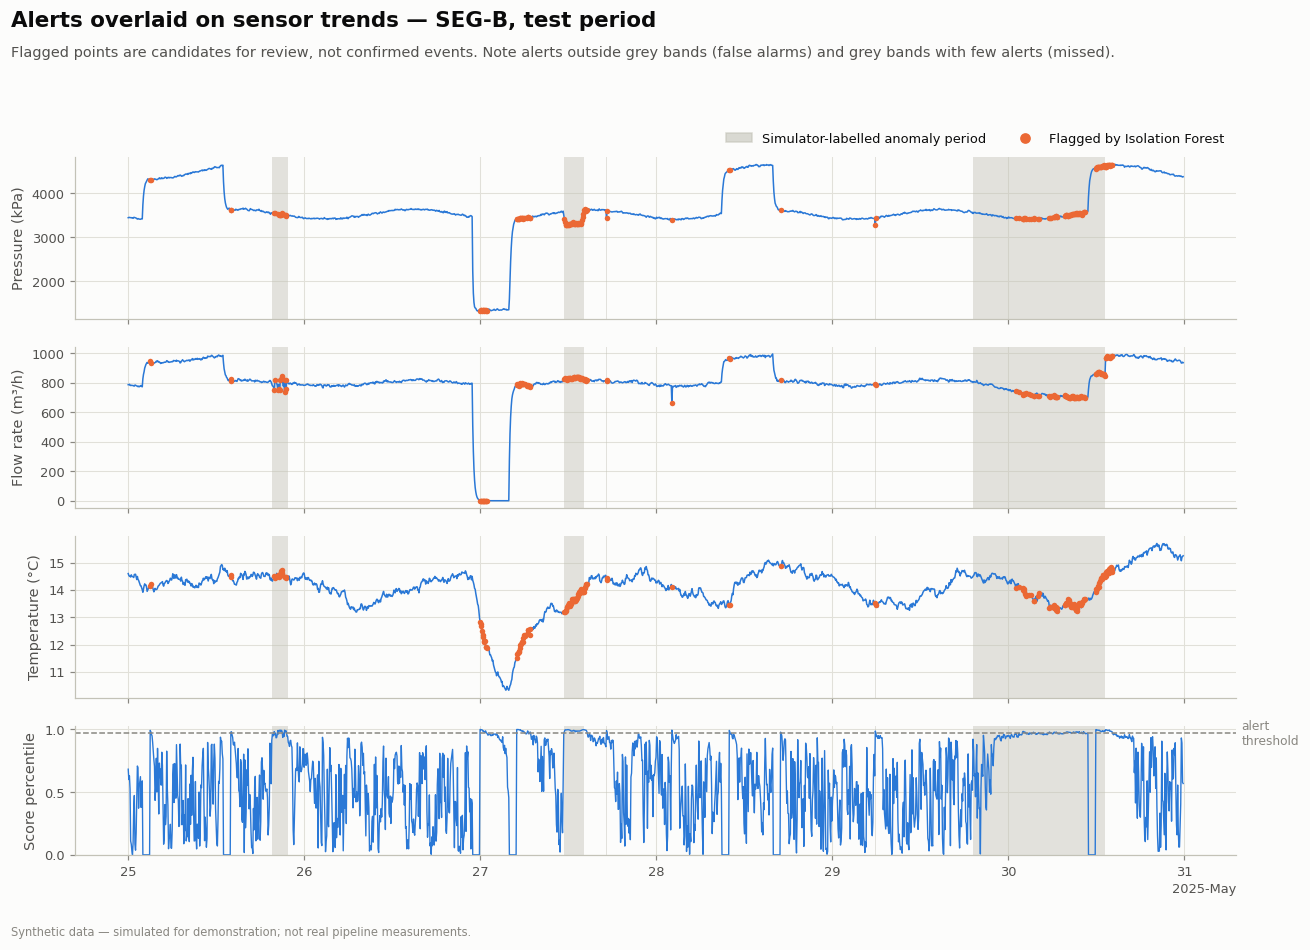

In [22]:
viz.fig_anomaly_overlay(results['test'], scored.thresholds); plt.show()

**What this shows.** Six days of one segment with Isolation Forest alerts. Alerts cluster inside labelled periods,
continue for a while after an event ends (rolling windows are still "recovering"), and also appear around the
shutdown, where temperature keeps moving for longer than the 60-minute settling window.

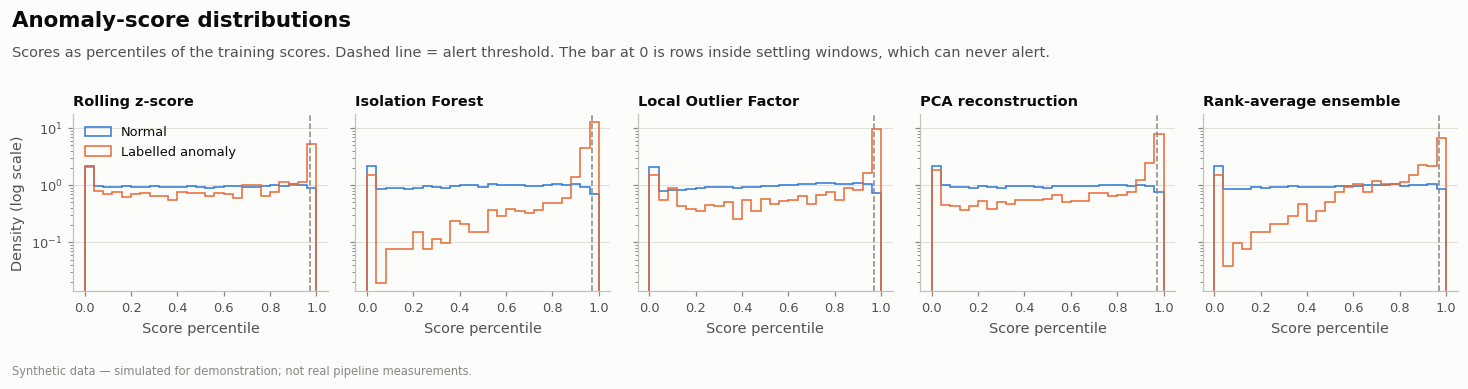

In [23]:
viz.fig_score_distributions(results['test'], 1 - cfg.ALERT_BUDGET); plt.show()

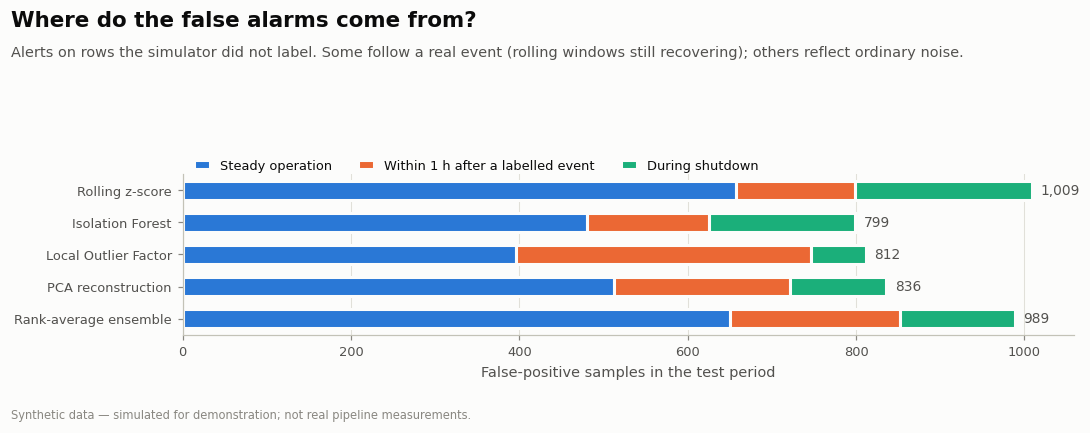

In [24]:
viz.fig_fp_breakdown(results['fp_breakdown']); plt.show()

In [25]:
pd.DataFrame(results['fp_breakdown']).T

,in_settling_window,during_shutdown,within_1h_after_event,steady_operation,total_false_positives
Rolling z-score,0,210,141,658,1009
Isolation Forest,0,174,144,481,799
Local Outlier Factor,0,66,350,396,812
PCA reconstruction,0,115,208,513,836
Rank-average ensemble,0,137,202,650,989


**False positives.** The largest share of false alarms occurs in steady operation: the ordinary tail of the noise
that any fixed alert budget will surface. A substantial share falls in the hour after a labelled event or during shutdown.
Neither is a "wrong" alert in an obvious sense, but both add review workload.

**Potential missed anomalies.** Slow drift, stuck sensors (for three of the four detectors), anything inside a
settling window, and anything during the warm-up or after a long data gap.

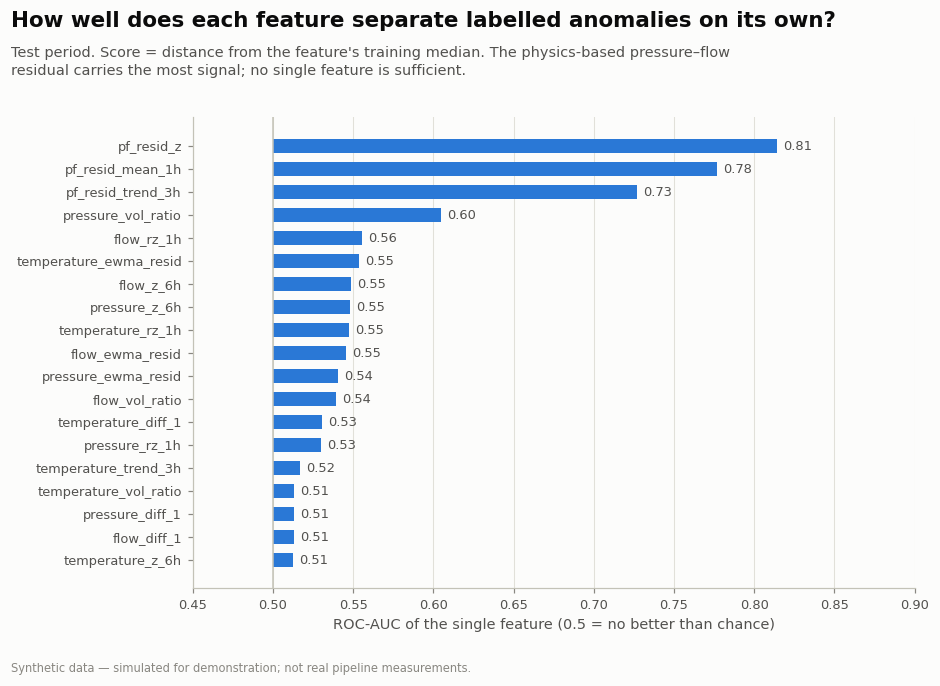

In [26]:
viz.fig_feature_auc(results['feature_auc']); plt.show()

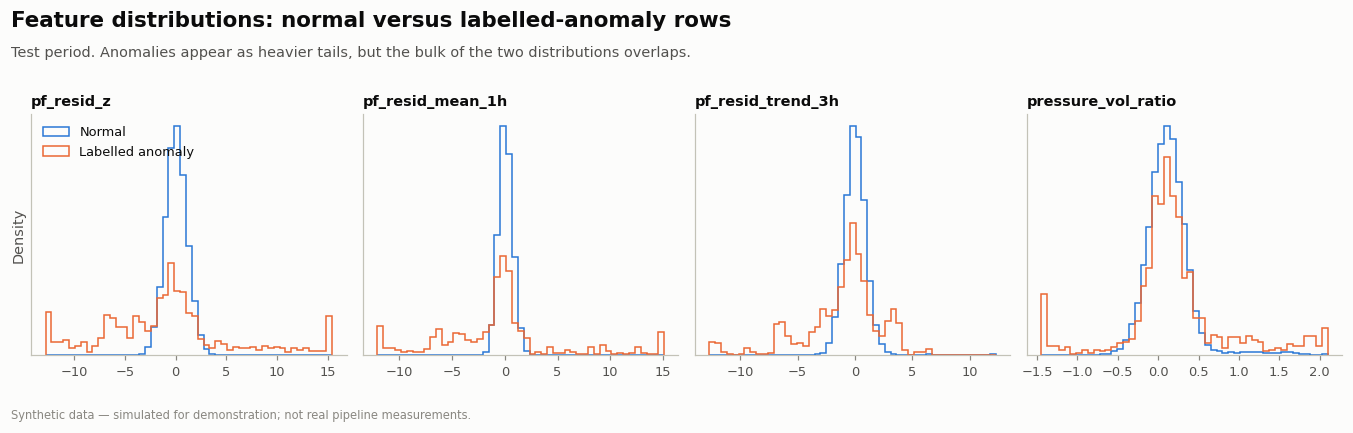

In [27]:
viz.fig_feature_distributions(scored.frame, results['feature_auc']['feature'].head(4).tolist()); plt.show()

**Feature analysis.** The physics-based pressure–flow residual features carry by far the most signal on their own;
per-sensor statistics are individually weak (each only sees the anomaly types that affect its own sensor). Domain
knowledge encoded as a feature was worth more than the choice of algorithm.

## 9. How this could support analysts

Used as a *screening aid*, anomaly scores could help analysts:

* **Review sensor data**: jump to the few percent of readings that look least like recent history instead of scanning trends.
* **Prioritise**: rank flagged periods by score and persistence so the most unusual are looked at first.
* **Report**: summarise alert counts by segment, sensor and period to show where unusual behaviour concentrates.
* **Investigate data quality**: stuck values, noise bursts and out-of-range readings are often instrument or
  telemetry problems; surfacing them protects downstream analytics.

It should **not** trigger automatic operational actions, and it is not a safety or leak-detection system. A flag
means "worth a look", nothing more. The full discussion is in `reports/business_analysis.md`.

In [28]:
# Example of an analyst-facing summary: alerts by segment in the test period (Isolation Forest)
test = results["test"]
summary = test.groupby("segment_id").agg(
    samples=("flag__iforest", "size"),
    alerts=("flag__iforest", "sum"),
    alert_rate=("flag__iforest", "mean"),
    highest_score_percentile=("pct__iforest", "max"),
)
summary

,samples,alerts,alert_rate,highest_score_percentile
segment_id,,,,
SEG-A,10368,353,0.034,1.0
SEG-B,10368,456,0.044,1.0
SEG-C,10368,231,0.022,1.0
SEG-D,10368,230,0.022,1.0


## 10. Limitations and next steps

**Limitations**

* **Synthetic data.** The simulator is far simpler than a real pipeline (no elevation profile, batching of
  different products, pump curves, valve operations, transients, weather, or instrument calibration cycles).
  Results do not transfer to real systems.
* **The anomaly patterns were designed by the same person who designed the features.** Real anomalies are not
  drawn from six tidy templates, so these metrics are optimistic about coverage of pattern *types*.
* **Small event counts** in the test period make per-pattern results uncertain.
* **Point-wise labels for long events** penalise detectors for not flagging the imperceptible start of a drift.
* **One design iteration was made after a first full run** (state-robust features, the settling rule and a longer
  simulation). The test period is therefore not perfectly untouched; no threshold or hyper-parameter was tuned on it.
* **Training data contains anomalies** (as it would in practice), which particularly affects density-based methods.

**Next steps**

* Validate on a public labelled rig dataset (e.g. the Skoltech Anomaly Benchmark) to test transfer to measured data.
* Alert persistence / event grouping so analysts see one item per episode rather than many points.
* A dedicated stuck-value rule and state-conditional baselines.
* Sequence models (e.g. an autoencoder on windows) for slow drift, compared against the simple baselines here.
* Per-alert explanations (which features drove the score).